# What drives contractor cost?

**Goal:** the box plots in `01_data_exploration.ipynb` show the bill differing a lot between buckets (damage type, inspection org, photos, quote stage, ...). Those plots look at one variable at a time, and the variables overlap: fire claims also have more photos, preliminary quotes also belong to bigger claims. Here every bucket becomes its own 0/1 feature in one linear model, so each effect is measured **with all other buckets held fixed**.

The model predicts `log(contractor_cost)` from the buckets. Each coefficient is read as **"% higher or lower bill than the reference bucket, everything else equal"**. The reference is the most common bucket of each variable.

1. Data and buckets
2. Cost model: what makes a claim expensive
3. How much could be saved
4. Summary: drivers and solutions

## 1. Data and buckets

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.ensemble import HistGradientBoostingRegressor
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY, GREEN = "#2b6cb0", "#dd6b20", "#a0aec0", "#38a169"
RNG = np.random.default_rng(42)

DATA = Path(os.environ.get("CLAIMS_DATA", "../data/tech_data_2026.xlsx"))
raw = pd.read_excel(DATA)
raw = raw.drop(columns=[c for c in raw.columns if c.startswith("Unnamed")])

In [2]:
# Same cleaning as 01_data_exploration.ipynb: one row per claim, final quote preferred
raw_dedup = raw.drop_duplicates()
clean_quote_df = (raw_dedup.assign(is_final=raw_dedup["quote_event"].eq("final quote"))
    .sort_values("is_final", ascending=True, kind="stable")
    .drop_duplicates(subset="quote_id", keep="last")
    .drop(columns="is_final")
    .reset_index(drop=True))
clean_claims_df = (clean_quote_df.assign(is_final=clean_quote_df["quote_event"].eq("final quote"))
    .sort_values("is_final", ascending=True, kind="stable")
    .drop_duplicates(subset="claim_id", keep="last")
    .drop(columns="is_final")
    .reset_index(drop=True))

# near-zero bills (< €100) are not real repair bills
df = clean_claims_df[clean_claims_df.contractor_cost >= 100].reset_index(drop=True)
print(f"claims: {len(clean_claims_df):,}  ->  modelled: {len(df):,}  (dropped {len(clean_claims_df) - len(df)} bills < €100)")

claims: 2,390  ->  modelled: 2,374  (dropped 16 bills < €100)


In [3]:
# Turn every column into buckets (one 0/1 feature per bucket later on)
# Only information available when the quote arrives; insurer/policyholder cost, decision and review flag are outcomes.
MIN_ORG = 30                              # orgs with fewer claims are pooled into "other orgs"

def make_buckets(d):
    b = pd.DataFrame(index=d.index)
    b["damage_type"] = d.inspection_type
    b["insurance_type"] = d.insurance_type.fillna("missing")
    b["building_type"] = d.building_type
    b["location"] = d.building_geographical_location
    b["quote_stage"] = d.quote_event
    org = d.inspection_org.fillna("missing")
    b["inspection_org"] = org.where(org.map(org.value_counts()).ge(MIN_ORG) | org.eq("missing"), "other orgs")
    b["construction_year"] = pd.cut(d.construction_year, [0, 1950, 1970, 1990, 2010, 2030],
                                    labels=["<1950", "1950–69", "1970–89", "1990–2009", "2010+"])
    b["building_area"] = pd.cut(d.building_area, [0, 80, 120, 200, 400, 1e6],
                                labels=["<80 m²", "80–120", "120–200", "200–400", "400+ m²"])
    b["inspection_images"] = pd.cut(d.inspection_images, [-1, 10, 20, 40, 1e4], labels=["0–10", "11–20", "21–40", "41+"])
    b["excess"] = pd.cut(d.insurance_excess_amount, [-1, 0, 5_000, 10_000, 1e7], labels=["0", "1–5k", "6–10k", "10k+"])
    return b.astype(object).where(b.notna(), "missing")

buckets = make_buckets(df)
pd.DataFrame({"buckets": buckets.nunique(), "reference (most common)": buckets.mode().iloc[0],
              "share in reference": [buckets[c].value_counts(normalize=True).iloc[0] for c in buckets]})

,buckets,reference (most common),share in reference
damage_type,5,Water damage,0.56
insurance_type,5,Water,0.58
building_type,3,House,0.72
location,2,urban,0.95
quote_stage,2,preliminary quote,0.56
inspection_org,9,other orgs,0.82
construction_year,6,1970–89,0.33
building_area,6,missing,0.54
inspection_images,4,0–10,0.33
excess,4,1–5k,0.47


In [4]:
def design(b, cols):
    """One 0/1 column per bucket; the most common bucket of each variable is the reference (dropped)."""
    parts, ref = [], {}
    for c in cols:
        ref[c] = b[c].value_counts().index[0]
        dm = pd.get_dummies(b[c], prefix=c, prefix_sep="=", dtype=float)
        parts.append(dm.drop(columns=f"{c}={ref[c]}"))
    X = pd.concat(parts, axis=1)
    return X, ref

def ols(X, y):
    A = np.column_stack([np.ones(len(X)), X])
    return np.linalg.lstsq(A, y, rcond=None)[0]

def predict(beta, X):
    return beta[0] + np.asarray(X) @ beta[1:]

def fit_effects(X, y, n_boot=500):
    """Coefficients with bootstrap 90% intervals, expressed as % effect on the bill."""
    beta = ols(X, y)
    boots = np.array([ols(X.iloc[i], y[i]) for i in (RNG.integers(0, len(y), len(y)) for _ in range(n_boot))])
    lo, hi = np.percentile(boots, [5, 95], axis=0)
    eff = pd.DataFrame({"feature": X.columns, "beta": beta[1:], "lo": lo[1:], "hi": hi[1:],
                        "n": X.sum().to_numpy().astype(int)})
    eff[["variable", "bucket"]] = eff.feature.str.split("=", n=1, expand=True)
    for c in ["beta", "lo", "hi"]:
        eff[c.replace("beta", "effect").replace("lo", "effect_lo").replace("hi", "effect_hi")] = np.expm1(eff[c])
    eff["clear"] = (eff.lo > 0) | (eff.hi < 0)          # 90% interval excludes "no effect"
    return beta, eff

def cv_scores(X, y, label):
    """5-fold CV: R² on the log scale and typical (median) % error on the € scale."""
    rows = []
    kf = KFold(5, shuffle=True, random_state=42)
    oof = {"mean only": np.zeros(len(y)), "linear (buckets)": np.zeros(len(y)), "gradient boosting (buckets)": np.zeros(len(y))}
    for tr, te in kf.split(X):
        oof["mean only"][te] = y[tr].mean()
        oof["linear (buckets)"][te] = predict(ols(X.iloc[tr], y[tr]), X.iloc[te])
        gb = HistGradientBoostingRegressor(max_iter=300, learning_rate=.05, max_leaf_nodes=15, random_state=42)
        oof["gradient boosting (buckets)"][te] = gb.fit(X.iloc[tr], y[tr]).predict(X.iloc[te])
    for m, p in oof.items():
        rows.append({"model": m, "R² (log)": 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum(),
                     "median abs % error": np.median(np.abs(np.expm1(p - y)))})
    return pd.DataFrame(rows).set_index("model").rename_axis(label), oof["linear (buckets)"]

GROUPS = {"damage & insurance type": ["damage_type", "insurance_type"]}   # strongly overlapping: fire damage ~ fire insurance

def importance(b, cols, y):
    """Drop one variable (or overlapping group) at a time: how much cross-validated R² is lost."""
    kf = KFold(5, shuffle=True, random_state=42)
    def r2(cs):
        X, _ = design(b, cs); p = np.zeros(len(y))
        for tr, te in kf.split(X):
            p[te] = predict(ols(X.iloc[tr], y[tr]), X.iloc[te])
        return 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    full = r2(cols)
    grouped = {g: m for g, m in GROUPS.items() if set(m) <= set(cols)}
    units = {**grouped, **{c: [c] for c in cols if not any(c in m for m in grouped.values())}}
    imp = pd.Series({u: full - r2([x for x in cols if x not in m]) for u, m in units.items()}).clip(lower=0).sort_values()
    return full, imp

In [5]:
ORDER = {
    "construction_year": ["<1950", "1950–69", "1970–89", "1990–2009", "2010+", "missing"],
    "building_area": ["<80 m²", "80–120", "120–200", "200–400", "400+ m²", "missing"],
    "inspection_images": ["0–10", "11–20", "21–40", "41+"],
    "excess": ["0", "1–5k", "6–10k", "10k+"],
}

def plot_effects(eff, ref, title, xlim=(-.7, 1.25)):
    """Small multiples: one panel per variable, % effect vs the reference bucket with 90% interval."""
    vars_ = list(ref)
    nrow = int(np.ceil(len(vars_) / 2))
    heights = [max(eff.variable.eq(v).sum() + 1, 2) for v in vars_]
    fig, axes = plt.subplots(nrow, 2, figsize=(14, 1.9 + .32 * sum(heights)),
                             gridspec_kw={"height_ratios": [max(heights[i:i + 2]) for i in range(0, len(vars_), 2)]})
    for ax, v in zip(axes.ravel(), vars_):
        e = eff[eff.variable == v].set_index("bucket")
        e.loc[ref[v], ["effect", "effect_lo", "effect_hi", "n", "clear"]] = [0, 0, 0, np.nan, False]
        if v in ORDER:
            e = e.reindex([k for k in ORDER[v] if k in e.index][::-1])
        else:
            e = e.sort_values("effect")
        y = np.arange(len(e))
        is_ref = e.index == ref[v]
        col = np.where(is_ref, GREY, np.where(~e.clear.astype(bool), GREY, np.where(e.effect > 0, ORANGE, BLUE)))
        ax.hlines(y, e.effect_lo, e.effect_hi, color=col, lw=2)
        ax.scatter(e.effect, y, color=col, s=36, zorder=3)
        ax.axvline(0, color="black", lw=.8)
        ax.set_yticks(y, [f"{k}  (reference)" if r else k for k, r in zip(e.index, is_ref)], fontsize=8)
        ax.set_xlim(*xlim)
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:+.0%}"))
        ax.set_title(v.replace("_", " "), fontsize=10, loc="left")
        ax.grid(axis="y", alpha=0)
    for ax in axes.ravel()[len(vars_):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=13)
    fig.supxlabel("effect on the bill vs reference bucket, all else equal   (orange/blue = 90% interval excludes 0; grey = unclear)", fontsize=9)
    fig.tight_layout(rect=[0, 0.02, 1, 0.98])
    plt.show()

def plot_importance(imp, full, title):
    fig, ax = plt.subplots(figsize=(8, .32 * len(imp) + 1))
    ax.barh([i.replace("_", " ") for i in imp.index], imp / full, color=BLUE)
    for i, v in enumerate(imp / full):
        ax.text(v + .005, i, f"{v:.0%}", va="center", fontsize=8)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
    ax.set(title=title, xlabel=f"share of explained variation lost when the variable is dropped (full model CV R² = {full:.2f})")
    ax.grid(axis="y", alpha=0)
    plt.show()
    return (imp / full).sort_values(ascending=False).rename("share of explained variation").to_frame()

## 2. Cost model: what makes a claim expensive

Target is `log(contractor_cost)`. The inspector's estimate is **left out on purpose**: it is the inspector's own forecast of the bill, so it would absorb the effects we want to see.

In [6]:
COLS_1 = ["damage_type", "insurance_type", "building_type", "location", "quote_stage", "inspection_org",
          "construction_year", "building_area", "inspection_images", "excess"]
y1 = np.log(df.contractor_cost.to_numpy())
X1, ref1 = design(buckets, COLS_1)
scores1, oof1 = cv_scores(X1, y1, "cost model: log(bill)")
print(f"{X1.shape[1]} bucket features, {len(y1):,} claims")
scores1

36 bucket features, 2,374 claims


,R² (log),median abs % error
cost model: log(bill),,
mean only,-0.00,0.62
linear (buckets),0.47,0.35
gradient boosting (buckets),0.47,0.32


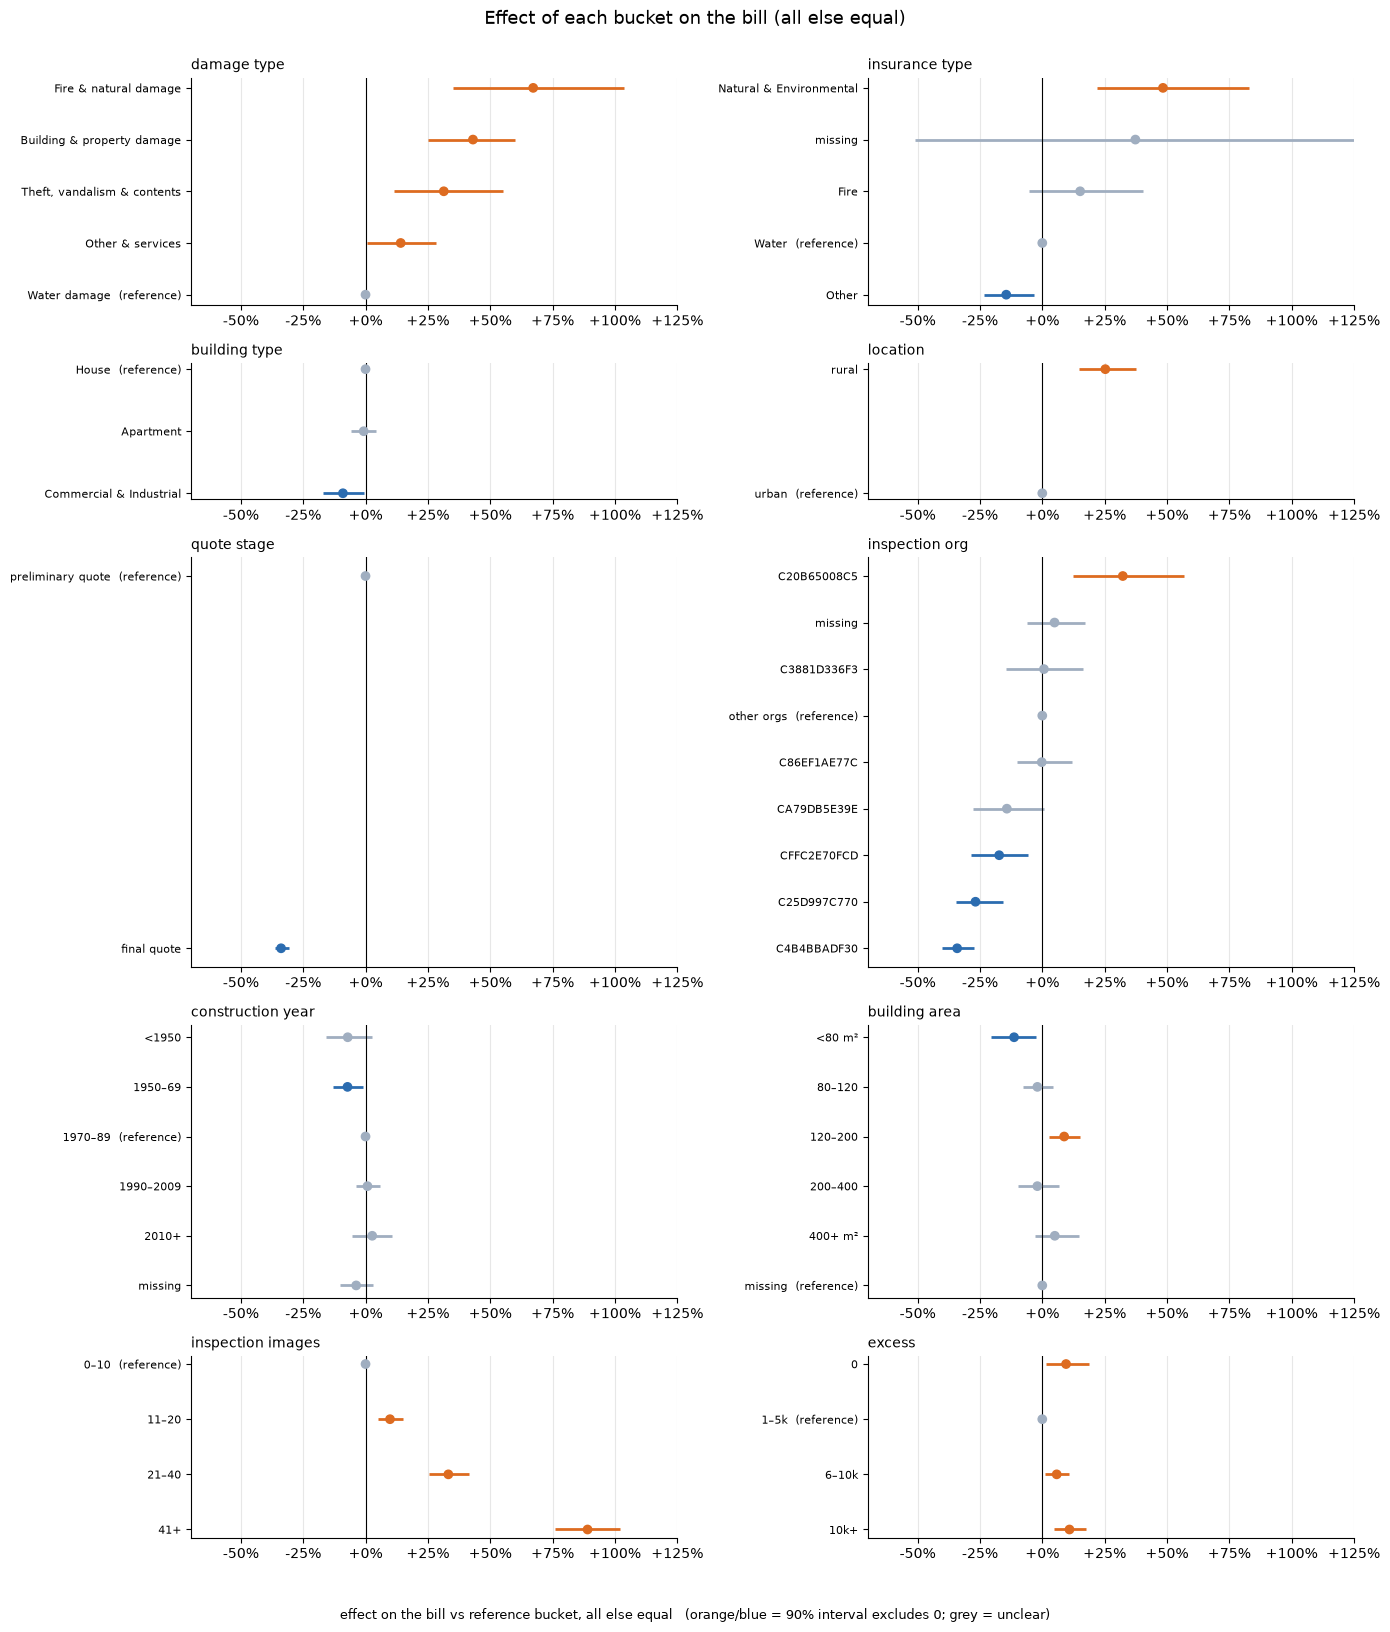

In [7]:
beta1, eff1 = fit_effects(X1, y1)
plot_effects(eff1, ref1, "Effect of each bucket on the bill (all else equal)")

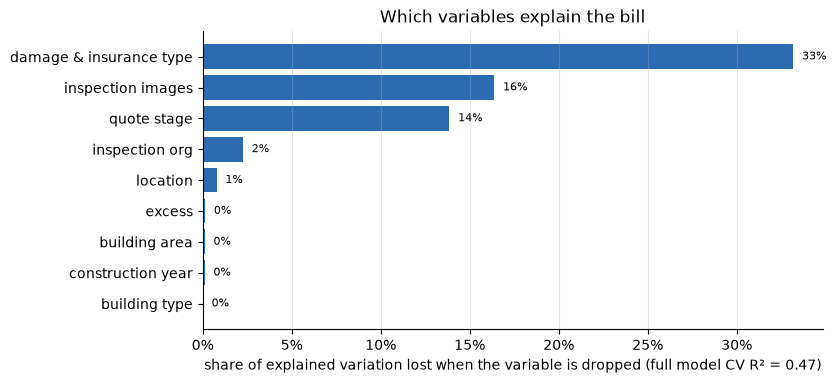

,share of explained variation
damage & insurance type,0.33
inspection_images,0.16
quote_stage,0.14
inspection_org,0.02
location,0.01
excess,0.00
building_area,0.00
construction_year,0.00
building_type,0.00


In [8]:
full1, imp1 = importance(buckets, COLS_1, y1)
plot_importance(imp1, full1, "Which variables explain the bill")

In [9]:
# Largest clear effects
show = ["variable", "bucket", "n", "effect", "effect_lo", "effect_hi"]
top1 = eff1[eff1.clear].sort_values("effect")
pd.concat([top1.tail(8), top1.head(6)])[show].sort_values("effect", ascending=False)

,variable,bucket,n,effect,effect_lo,effect_hi
32,inspection_images,41+,409,0.89,0.76,1.02
1,damage_type,Fire & natural damage,525,0.67,0.35,1.04
5,insurance_type,Natural & Environmental,260,0.48,0.22,0.83
0,damage_type,Building & property damage,223,0.43,0.25,0.60
31,inspection_images,21–40,414,0.33,0.25,0.42
12,inspection_org,C20B65008C5,32,0.32,0.12,0.57
3,damage_type,"Theft, vandalism & contents",62,0.31,0.11,0.55
10,location,rural,126,0.25,0.15,0.38
29,building_area,<80 m²,115,-0.11,-0.20,-0.03
6,insurance_type,Other,448,-0.14,-0.23,-0.03


**Takeaway:** the buckets explain about half of the variation in the bill (CV R² 0.47, typical error ±35%). Gradient boosting on the same features does no better (0.47), so the effects are mostly additive and the linear reading is fair.

- **Damage and insurance type explain the most** (a third of the explained variation, measured together because they overlap). All else equal, fire & natural damage costs **+67%** and building damage **+43%** more than water damage. Natural & Environmental cover adds **+48%**.
- **Photo count is the second signal (16%):** 41+ photos **+89%**, 21–40 photos **+33%** vs 0–10. Bigger damage gets more photos, so this measures damage size, not a cause.
- **Quote stage (14%):** final quotes are **−34%** below preliminary ones for comparable claims.
- **Inspection org is a small driver (2%):** among orgs with ≥30 claims, C4B4BBADF30 (−34%), C25D997C770 (−27%) and CFFC2E70FCD (−17%) are cheaper, while C20B65008C5 is **+32%** dearer.
- **Rural** claims cost **+25%**.
- **Building age, area, building type and excess explain essentially nothing** once the other buckets are known. The one exception is small buildings (<80 m²), at −11%.

## 3. How much could be saved

The model is **correlational**: it shows where bills are high after accounting for the other buckets, not what would happen if something were changed. The figures below are therefore **upper-bound sizings** to rank levers, not promised savings.

Two views:
1. **Partner lever what-if:** for inspection orgs with a clear positive effect, what if their claims came in at the level of the reference ("other orgs")? Damage type, photo count, location and quote stage are *not* treated as levers: they describe the claim, and changing them would not make the repair cheaper.
2. **Excess over fair cost:** the model gives each claim a "fair" bill = the typical bill for claims with the same buckets (out-of-fold, so a claim's own bill is never used). The typical model error is about ±35%, so only the part of a bill above **1.5× the fair bill** is counted as excess. How much money sits there, and does today's review look at it?

In [10]:
LEVERS = ["inspection_org"]                             # partner steering: the insurer chooses / gives feedback to orgs
d2, b2 = df, buckets
rows = []
for _, e in eff1[eff1.variable.isin(LEVERS) & eff1.clear & (eff1.effect > 0)].iterrows():
    sel = b2[e.variable] == e.bucket
    paid = d2.contractor_cost[sel].sum()
    rows.append({"lever": e.variable, "bucket": e.bucket, "claims": int(sel.sum()), "paid (€k)": paid / 1e3,
                 "overrun vs reference": e.effect, "what-if saving (€k)": paid * (1 - np.exp(-e.beta)) / 1e3})
levers = pd.DataFrame(rows).sort_values("what-if saving (€k)", ascending=False)
total_paid = df.contractor_cost.sum()
print(f"total paid on modelled claims: €{total_paid / 1e6:,.1f}m")
levers

total paid on modelled claims: €146.1m


,lever,bucket,claims,paid (€k),overrun vs reference,what-if saving (€k)
0,inspection_org,C20B65008C5,32,"2,689.90",0.32,656.47


In [11]:
TOL = 1.5                                               # tolerance band above the fair bill (beyond typical model error)
fair = np.exp(oof1)                                     # out-of-fold, so each claim's own bill is not used
excess = (d2.contractor_cost - TOL * fair).clip(lower=0)
summary = (pd.DataFrame({"review": d2.manual_review.map({True: "manual review", False: "auto-processed"}),
                         "paid": d2.contractor_cost, "excess": excess, "above": excess > 0})
           .groupby("review").agg(claims=("paid", "size"), paid_eur_k=("paid", lambda s: s.sum() / 1e3),
                                  claims_above_band=("above", "sum"), excess_eur_k=("excess", lambda s: s.sum() / 1e3)))
summary["excess share of paid"] = summary.excess_eur_k / summary.paid_eur_k
summary

,claims,paid_eur_k,claims_above_band,excess_eur_k,excess share of paid
review,,,,,
auto-processed,1815,"107,256.35",385,"12,633.53",0.12
manual review,559,"38,870.76",116,"7,937.40",0.20


In [12]:
# Where does the excess sit? Damage type x review status
pd.crosstab(b2.damage_type, d2.manual_review.map({True: "manual review", False: "auto-processed"}),
            values=excess / 1e3, aggfunc="sum", margins=True).round(0).rename_axis(index="excess €k by damage type", columns=None)

,auto-processed,manual review,All
excess €k by damage type,,,
Building & property damage,987.00,0.00,987.00
Fire & natural damage,"1,287.00","2,426.00","3,713.00"
Other & services,"1,390.00",549.00,"1,938.00"
"Theft, vandalism & contents",397.00,457.00,854.00
Water damage,"8,573.00","4,506.00","13,078.00"
All,"12,634.00","7,937.00","20,571.00"


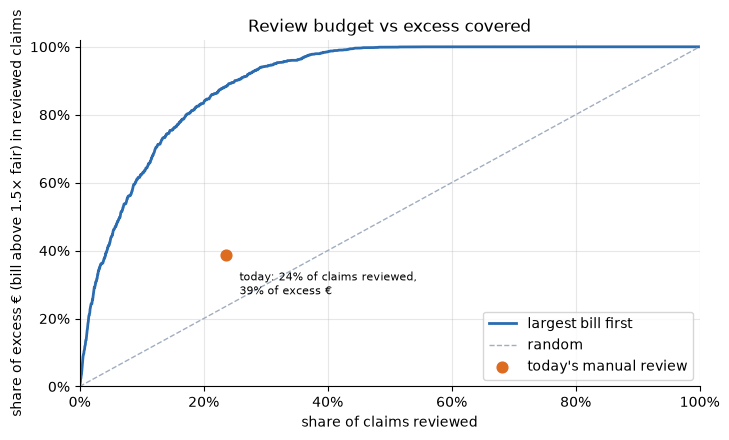

,share of excess € covered
review budget = 24% of claims,
today's manual review,0.39
largest bill first,0.88
random,0.24


In [13]:
# Does today's review look at the excess? Compare with simple review rules at the same budget.
ex = excess.to_numpy()
rev = d2.manual_review.to_numpy()
k = np.arange(1, len(ex) + 1) / len(ex)
by_size = np.cumsum(ex[np.argsort(-d2.contractor_cost.to_numpy())]) / ex.sum()
today = (rev.mean(), ex[rev].sum() / ex.sum())
fig, ax = plt.subplots()
ax.plot(k, by_size, color=BLUE, lw=2, label="largest bill first")
ax.plot([0, 1], [0, 1], color=GREY, lw=1, ls="--", label="random")
ax.scatter(*today, color=ORANGE, s=60, zorder=3, label="today's manual review")
ax.annotate(f"today: {today[0]:.0%} of claims reviewed,\n{today[1]:.0%} of excess €", today, textcoords="offset points", xytext=(10, -28), fontsize=8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set(xlabel="share of claims reviewed", ylabel="share of excess € (bill above 1.5× fair) in reviewed claims",
       title="Review budget vs excess covered", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower right")
plt.show()
i = int(today[0] * len(ex))
pd.DataFrame({"share of excess € covered": {"today's manual review": today[1], "largest bill first": by_size[i - 1],
              "random": today[0]}}).rename_axis(f"review budget = {today[0]:.0%} of claims")

In [14]:
# Save the effect tables for reporting
Path("../outputs").mkdir(exist_ok=True)
eff1[
    ["variable", "bucket", "n", "effect", "effect_lo", "effect_hi", "clear"]].to_csv("../outputs/cost_driver_effects.csv", index=False)

**Takeaway:**
- **€20.6m (14% of the €146.1m paid) sits above 1.5× the fair bill**, spread over 501 claims. 61% of it (€12.6m, 385 claims) is in **auto-processed** claims that nobody looked at. Water damage holds 64% (€13.1m).
- **Today's review covers 39% of the excess € with 24% of the claims.** That is better than random (24%), but with the same budget "largest bill first" would cover **88%**. Moving the review budget is by far the biggest lever.
- Only part of the covered excess would actually be recovered through negotiation or rejection. Every 10% of the excess recovered is worth about €2m.
- **The partner lever is small:** only one org (C20B65008C5) is clearly more expensive. Bringing it to the reference level would save at most **€0.7m** (upper bound, correlational).
- The fair bill here does not use the inspector's estimate, so part of the "excess" is damage size that the buckets can't see. Treat the €20.6m as the size of the pool to look into, not as overpayment.

## 4. Summary: drivers and solutions

**What drives the bill** (all else equal, CV R² 0.47):
1. **Damage & insurance type** (a third of the explained variation): fire & natural damage **+67%**, building damage +43% and theft +31% vs water. Natural & Environmental cover adds +48%.
2. **Damage size, as seen in photo count** (16%): 41+ photos +89%, 21–40 photos +33%.
3. **Quote stage** (14%): final quotes −34% vs preliminary.
4. **Inspection org** (2%): C20B65008C5 +32%; C4B4BBADF30 −34%, C25D997C770 −27%, CFFC2E70FCD −17%.
5. **Rural location**: +25%.
6. **No effect:** building age, area (except <80 m², −11%), building type and policy excess.

| # | Solution | Based on | Size of the prize |
|---|---|---|---|
| 1 | **Re-target manual review**: rank claims by bill size and by bill above the fair cost for their buckets | Today's review covers 39% of excess € with 24% of claims; largest-bill-first covers 88% at the same budget | €20.6m sits above 1.5× fair cost, €12.6m of it unreviewed. Each 10% recovered ≈ €2m |
| 2 | **Segment-specific benchmarks**: judge a bill against claims of the same damage type, insurance type, size (photos) and stage, not one flat threshold | Damage/insurance type and photos explain most of the bill | Avoids flagging normal fire claims and finds expensive water claims (64% of the excess) |
| 3 | **Do not settle on preliminary quotes alone**: ask for a final or itemised quote when a preliminary quote is above fair cost | Final quotes are 34% lower for comparable claims | Part of the pool above; needs the business to confirm how the two stages relate |
| 4 | **Partner management**: review org C20B65008C5 and learn from the orgs that come in cheaper (C4B4BBADF30, C25D997C770) | Org explains about 2% of the variation | ≤ €0.7m |
| 5 | **Prevention / portfolio** (not per claim): fire, natural and rural risks cost the most per claim; water is the most frequent and holds most of the excess | Damage type, location | Underwriting and prevention topic, not claims handling |

**Limits:**
- The effects are correlational, not causal, so the € figures size and rank the levers rather than promise savings.
- Half of the variation is unexplained: there are no line items or repair scope.
- The data is one row per claim (final quote preferred), so half of the quotes were dropped.
- The excess pool depends on the fair-cost definition and on the 1.5× tolerance.
- **Next step:** validate solution 1 with a random audit of auto-approved claims that sit above the band.